**Synthetic data.** Everything this notebook produces is artificial. No real company, customer or campaign is behind it.

# Generate a synthetic weekly MMM dataset

All Else Equal Analytics · Marketing analytics · Causal inference

This notebook runs the simulator in `src/simulate_mmm.py` with a config from `configs/`, checks the result, and saves two files:

| File | What it holds |
|---|---|
| `data/synthetic_mmm_data.csv` | The **observed** columns only: what an analyst would receive from a client. |
| `data/ground_truth.json` | The **hidden truth**: parameters, per-week contributions, realized diagnostics. Never use it while fitting a model. |

**How to use it:** run the cells top to bottom. The only settings you need to touch are in section 1. To change the business itself, edit the config (see `docs/config_guide.md`).

## 1. Settings

In [1]:
import json
import sys
import textwrap
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_repo_root() -> Path:
    """Find the repo root (the folder with pyproject.toml and src/simulate_mmm.py).

    Looks upward from the notebook's own folder (VS Code provides it) and then from the
    folder Jupyter started in, so it works however the notebook was opened.
    """
    starts = []
    if "__vsc_ipynb_file__" in globals():
        starts.append(Path(globals()["__vsc_ipynb_file__"]).resolve().parent)
    starts.append(Path.cwd().resolve())
    for start in starts:
        for folder in (start, *start.parents):
            if (folder / "pyproject.toml").exists() and (
                folder / "src" / "simulate_mmm.py"
            ).exists():
                return folder
    raise FileNotFoundError(
        f"Could not find the repo root from {[str(s) for s in starts]}. "
        "Open the notebook from inside "
        "the mmm-ground-truth folder, or set REPO = Path('/full/path/to/mmm-ground-truth')."
    )


REPO = find_repo_root()
sys.path.insert(0, str(REPO / "src"))
from simulate_mmm import _jsonable, load_config, self_check, simulate  # noqa: E402

CONFIG_PATH = REPO / "configs" / "config_v1.yaml"
SEED = None  # None = use seeds.primary from the config. Set an integer to draw another dataset.
OUT_DIR = REPO / "data"
# print(f"Repo root: {REPO}")

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

### Chart style

One rule for every chart here: everything grey, and one thing in mulberry, the thing to look at.

In [2]:
MULBERRY = "#8C2552"
INK = "#1F2430"
SLATE = "#4B5563"
LABEL = "#6B7280"
MID = "#9CA3AF"
LIGHT = "#D1D5DB"

plt.rcParams.update(
    {
        "font.family": ["Source Sans 3", "DejaVu Sans"],
        "axes.edgecolor": MID,
        "axes.labelcolor": LABEL,
        "xtick.color": LABEL,
        "ytick.color": LABEL,
        "text.color": SLATE,
        "axes.titlecolor": INK,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
        "legend.frameon": False,
        "figure.dpi": 110,
    }
)


def finish(ax, title, source):
    """Left-aligned takeaway title and a source line in label grey."""
    ax.set_title(textwrap.fill(title, 88), pad=12)
    ax.figure.text(0.01, -0.04, source, fontsize=9, color=LABEL, ha="left")

## 2. Load the config

The config is the whole recipe: calendar, baseline demand, promotions, and every channel's carryover, saturation and budget rules. Its SHA-256 hash is stored in `ground_truth.json`, so a dataset can always be traced to the exact config that made it.

In [3]:
cfg, config_sha = load_config(CONFIG_PATH)
seed = cfg["seeds"]["primary"] if SEED is None else SEED

print(f"config version : {cfg['config_version']}")
print(f"config sha256  : {config_sha[:16]}...")
print(f"seed           : {seed}")
print(f"weeks          : {cfg['calendar']['n_weeks']} starting {cfg['calendar']['start_date']}")
print(f"confounding    : {'on' if cfg['confounding']['enabled'] else 'off'}")

plan = pd.DataFrame(
    [
        {
            "channel": name,
            "exposure": ch["exposure"],
            "mean spend (k USD/wk)": ch["mean_spend"],
            "adstock": ch["adstock"]["type"],
            "decay": ch["adstock"]["decay"],
            "half-sat. k": ch["saturation"]["k"],
            "max effect (beta)": ch["beta"],
            "chases sales": ch["budget"]["chase"],
        }
        for name, ch in cfg["channels"].items()
    ]
).set_index("channel")
plan

config version : 1.0.0
config sha256  : 4f69cafb592ab0f0...
seed           : 2026
weeks          : 156 starting 2022-01-03
confounding    : on


,exposure,mean spend (k USD/wk),adstock,decay,half-sat. k,max effect (beta),chases sales
channel,,,,,,,
tv,spend,60.0,geometric,0.6,150.0,220.0,0.0
ooh,spend,20.0,geometric,0.3,60.0,110.0,0.0
meta,impressions,40.0,geometric,0.4,10.0,175.0,2.0
youtube_display,impressions,30.0,geometric,0.5,12.0,90.0,1.0
search,clicks,25.0,geometric,0.2,30.0,150.0,3.0


## 3. Generate the dataset

`simulate` is a pure function of the config and the seed, so the same pair always gives the same data. It runs week by week because spend at week *t* depends on sales at week *t - 1*.

In [4]:
obs, truth = simulate(cfg, seed, config_sha256=config_sha)
self_check(obs, truth, cfg)  # raises if the data is malformed or a hidden column leaked
print(f"OK: {obs.shape[0]} weeks x {obs.shape[1]} observed columns. Self-check passed.")
obs.head()

OK: 156 weeks x 18 observed columns. Self-check passed.


,week_start,t,sales,tv_spend,ooh_spend,meta_spend,meta_impressions,youtube_display_spend,youtube_display_impressions,search_spend,search_clicks,organic_search_volume,promo_flag,holiday_flag,fourier_sin1,fourier_cos1,fourier_sin2,fourier_cos2
0,2022-01-03,0,1468.437437,67.513443,21.487745,45.715420,5.305685,24.807724,4.209003,31.229995,52.041689,268.344973,0,0,0.103031,0.994678,0.204966,0.978769
1,2022-01-10,1,1455.310027,85.512130,20.754225,48.044811,5.453849,31.393865,6.795153,30.848073,52.602940,348.549256,0,0,0.221772,0.975099,0.432499,0.901634
2,2022-01-17,2,1381.771947,76.202317,18.238930,45.618444,4.950272,40.256995,6.126264,27.435805,46.345365,293.791528,0,0,0.337301,0.941397,0.635068,0.772456
3,2022-01-24,3,1315.048964,51.531714,24.217590,34.452421,3.770864,31.962138,6.011059,23.650631,41.209733,370.063802,0,0,0.447945,0.894061,0.800980,0.598691
4,2022-01-31,4,1368.424486,61.147668,19.512745,36.845145,4.298290,22.072497,4.772259,22.015914,40.055149,284.440600,0,0,0.552101,0.833777,0.920659,0.390368


### What each observed column means

In [5]:
DESCRIPTIONS = {
    "week_start": "Monday that starts the week (ISO date)",
    "t": "Week number from 0 (a linear time trend)",
    "sales": "Weekly sales, thousand USD. This is the KPI.",
    "organic_search_volume": (
        "Search queries, thousands. A noisy measure of demand, usable as a control for Search."
    ),
    "promo_flag": "1 in promotion weeks, else 0",
    "holiday_flag": "1 in the Black Friday week and the week containing Dec 24, else 0",
}


def describe(col):
    if col in DESCRIPTIONS:
        return DESCRIPTIONS[col]
    if col.endswith("_spend"):
        return "Weekly spend, thousand USD"
    if col.endswith("_impressions"):
        return "Impressions delivered, millions"
    if col.endswith("_clicks"):
        return (
            "Clicks, thousands (includes clicks from people who would have bought anyway; "
            "see section 5)"
        )
    if col.startswith("fourier_"):
        return "Seasonality term: sine or cosine of the day of the year (harmonic 1 or 2)"
    return ""


pd.DataFrame({"column": obs.columns, "meaning": [describe(c) for c in obs.columns]}).set_index(
    "column"
)

,meaning
column,
week_start,Monday that starts the week (ISO date)
t,Week number from 0 (a linear time trend)
sales,"Weekly sales, thousand USD. This is the KPI."
tv_spend,"Weekly spend, thousand USD"
ooh_spend,"Weekly spend, thousand USD"
meta_spend,"Weekly spend, thousand USD"
meta_impressions,"Impressions delivered, millions"
youtube_display_spend,"Weekly spend, thousand USD"
youtube_display_impressions,"Impressions delivered, millions"


## 4. What is hidden

Everything below lives only in `ground_truth.json`. Each hidden series is prefixed `true_` so it cannot be mistaken for an observed column. **Model on the observed columns only.** Reading these while fitting is leakage, and any result built on it is worthless.

In [6]:
hidden = [k for k in truth["weekly"] if k != "week_start"]
print(f"{len(hidden)} hidden weekly series, none present in the observed data:\n")
for name in hidden:
    print("  ", name)
assert not set(hidden) & set(obs.columns)

29 hidden weekly series, none present in the observed data:

   true_baseline_before_shock
   true_latent_demand_shock
   true_promo_uplift
   true_sales_noise
   true_seasonal_index_Z
   true_query_volume
   true_search_demand_clicks
   true_search_incremental_clicks
   true_budget_performance_signal_g
   true_tv_exposure
   true_tv_price
   true_tv_adstock
   true_tv_contribution
   true_ooh_exposure
   true_ooh_price
   true_ooh_adstock
   true_ooh_contribution
   true_meta_exposure
   true_meta_price
   true_meta_adstock
   true_meta_contribution
   true_youtube_display_exposure
   true_youtube_display_price
   true_youtube_display_adstock
   true_youtube_display_contribution
   true_search_exposure
   true_search_price
   true_search_adstock
   true_search_contribution


## 5. Look at what was built

Four charts to check the dataset looks like a plausible business before anyone models it. They use hidden truth where needed and say so.

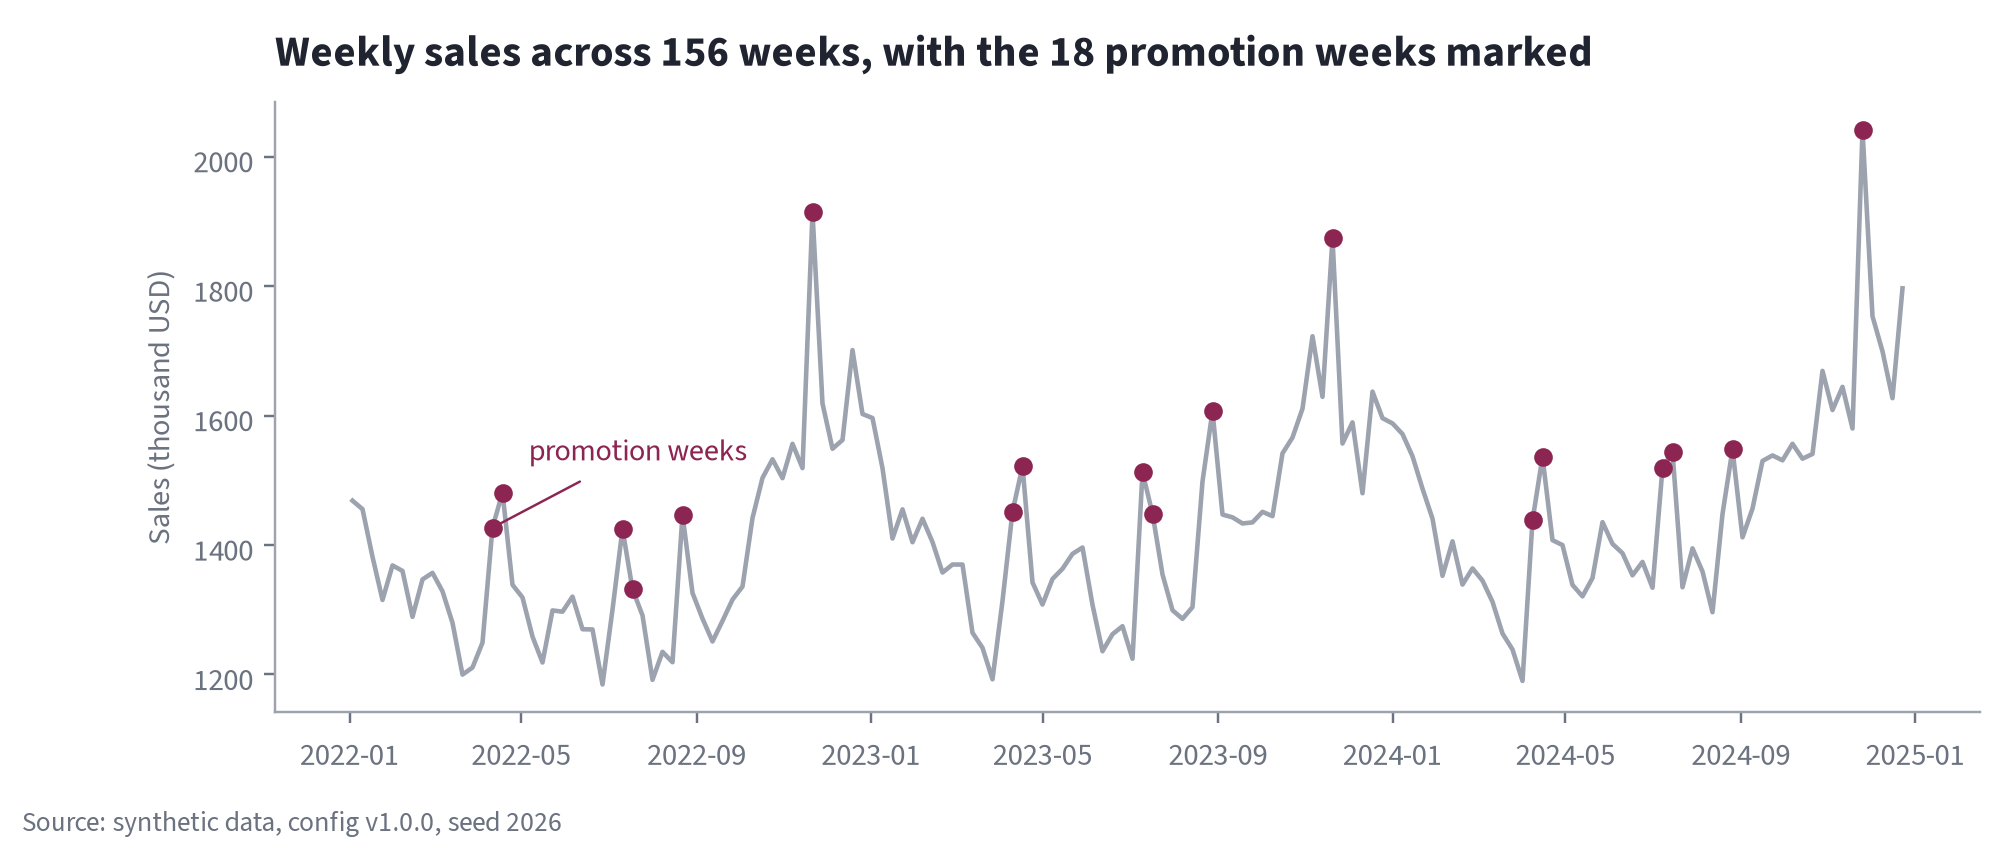

In [7]:
SOURCE = f"Source: synthetic data, config v{cfg['config_version']}, seed {seed}"
dates = pd.to_datetime(obs["week_start"])

# 1) Sales with promo weeks marked
promo = obs["promo_flag"] == 1
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(dates, obs["sales"], color=MID, lw=1.5)
ax.scatter(dates[promo], obs["sales"][promo], color=MULBERRY, s=26, zorder=3)
ax.annotate(
    "promotion weeks",
    xy=(dates[promo].iloc[0], obs["sales"][promo].iloc[0]),
    xytext=(12, 22),
    textcoords="offset points",
    color=MULBERRY,
    fontsize=10,
    arrowprops=dict(arrowstyle="-", color=MULBERRY, lw=0.8),
)
ax.set_ylabel("Sales (thousand USD)")
finish(
    ax,
    f"Weekly sales across {len(obs)} weeks, with the {int(promo.sum())} promotion weeks marked",
    SOURCE,
)
plt.show()

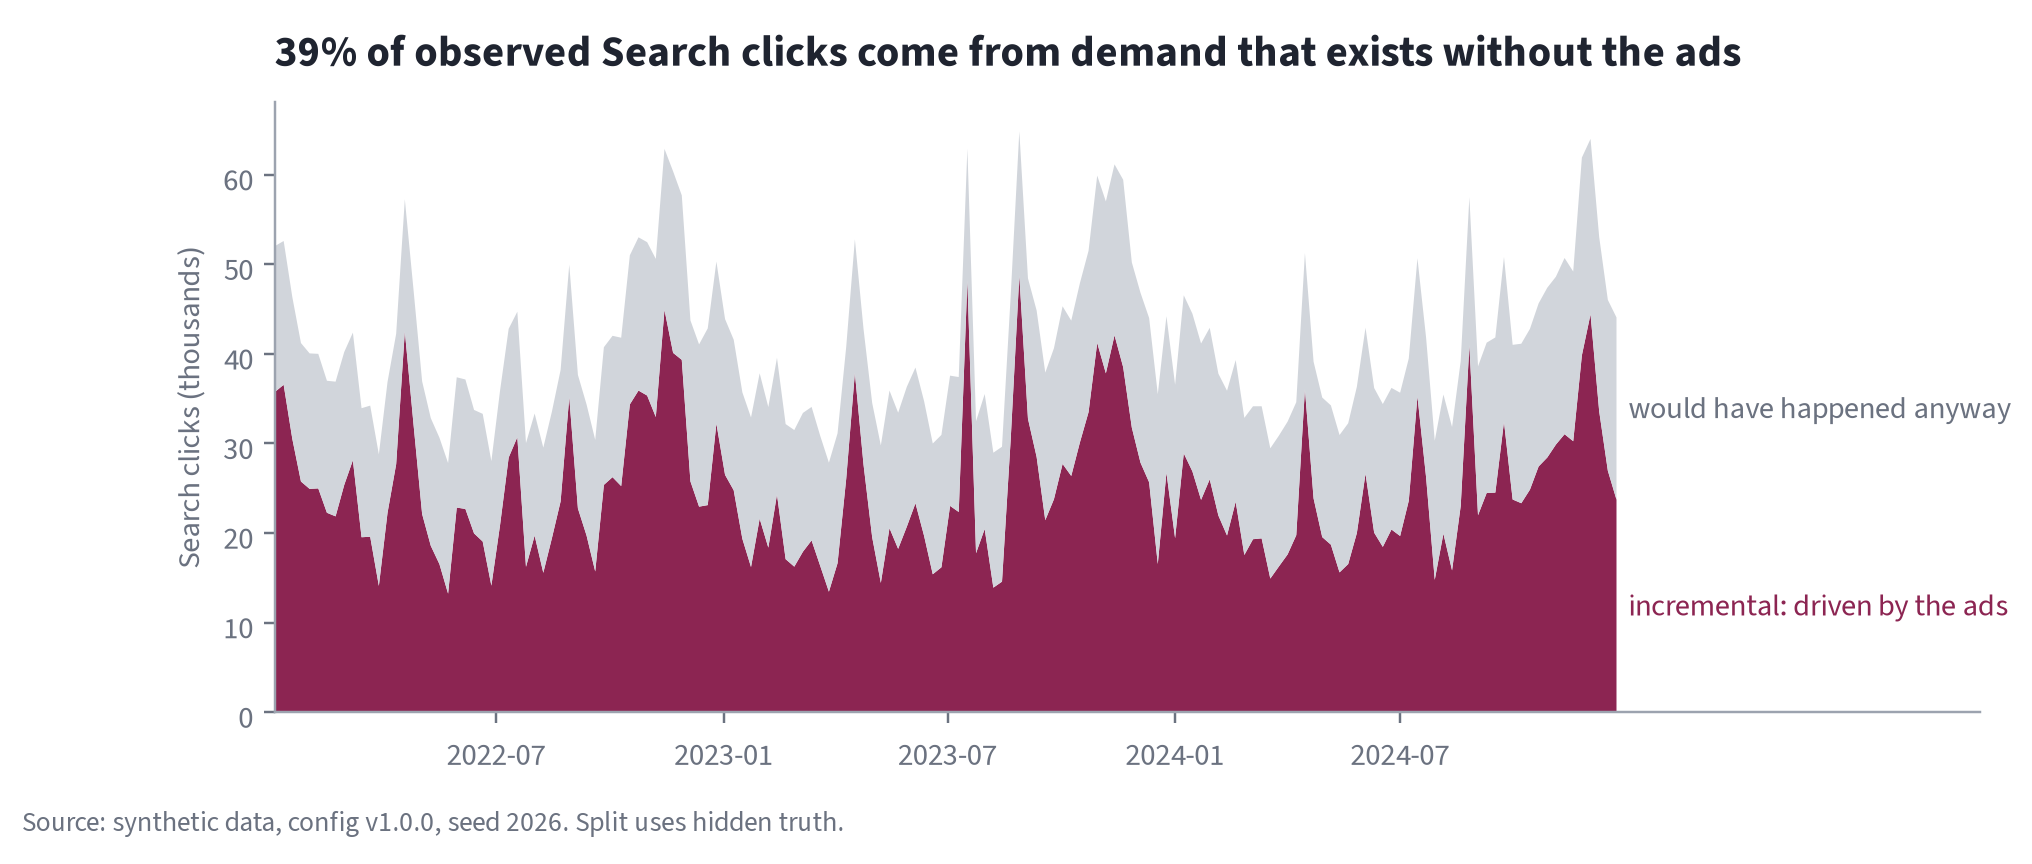

In [8]:
# 2) Search clicks: how many would have happened anyway? (uses hidden truth)
w = truth["weekly"]
incremental = np.asarray(w["true_search_incremental_clicks"])
demand = np.asarray(w["true_search_demand_clicks"])
share_demand = demand.sum() / (incremental + demand).sum()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.stackplot(dates, incremental, demand, colors=[MULBERRY, LIGHT], linewidth=0)
ax.text(
    dates.iloc[-1],
    incremental[-1] / 2,
    "  incremental: driven by the ads",
    color=MULBERRY,
    va="center",
    fontsize=10,
)
ax.text(
    dates.iloc[-1],
    incremental[-1] + demand[-1] / 2,
    "  would have happened anyway",
    color=LABEL,
    va="center",
    fontsize=10,
)
ax.set_xlim(dates.iloc[0], dates.iloc[-1] + pd.Timedelta(weeks=42))
ax.set_xticks([t for t in ax.get_xticks() if t <= mdates.date2num(dates.iloc[-1])])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_ylabel("Search clicks (thousands)")
finish(
    ax,
    f"{share_demand:.0%} of observed Search clicks come from demand that exists without the ads",
    SOURCE + ". Split uses hidden truth.",
)
plt.show()

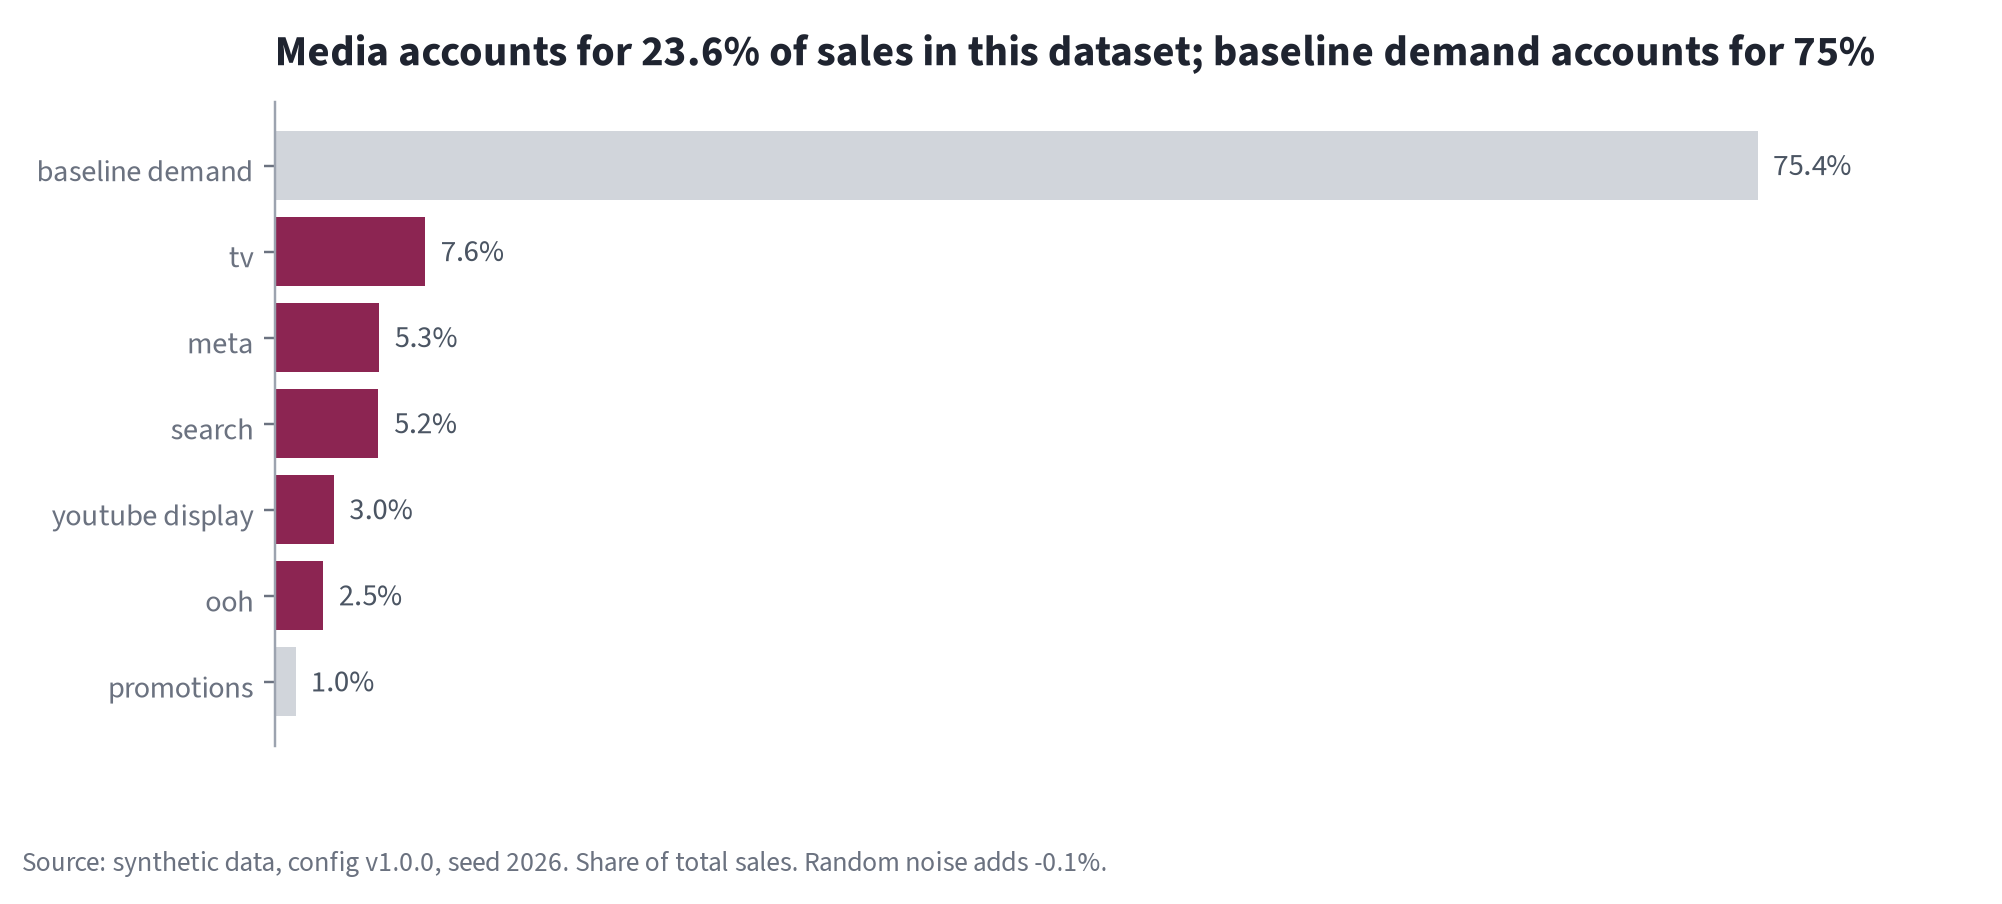

In [9]:
# 3) Where do sales come from? Share of total sales by component (uses hidden truth)
sales_total = obs["sales"].sum()
parts = {
    "baseline demand": (
        np.asarray(w["true_baseline_before_shock"]) * np.asarray(w["true_latent_demand_shock"])
    ).sum(),
    "promotions": np.asarray(w["true_promo_uplift"]).sum(),
}
media_names = list(cfg["channels"])
for k in media_names:
    parts[k.replace("_", " ")] = np.asarray(w[f"true_{k}_contribution"]).sum()
shares = pd.Series(parts) / sales_total
noise_share = np.asarray(w["true_sales_noise"]).sum() / sales_total  # averages out to about zero
media_share = shares[[k.replace("_", " ") for k in media_names]].sum()

order = shares.sort_values()
colors = [
    MULBERRY if name in {k.replace("_", " ") for k in media_names} else LIGHT
    for name in order.index
]
fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.barh(order.index, order.values, color=colors)
for b, v in zip(bars, order.values, strict=True):
    ax.text(
        v + 0.008, b.get_y() + b.get_height() / 2, f"{v:.1%}", va="center", fontsize=10, color=SLATE
    )
ax.set_xlim(0, order.max() * 1.15)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
finish(
    ax,
    f"Media accounts for {media_share:.1%} of sales in this dataset; "
    f"baseline demand accounts for {shares['baseline demand']:.0%}",
    SOURCE + f". Share of total sales. Random noise adds {noise_share:+.1%}.",
)
plt.show()

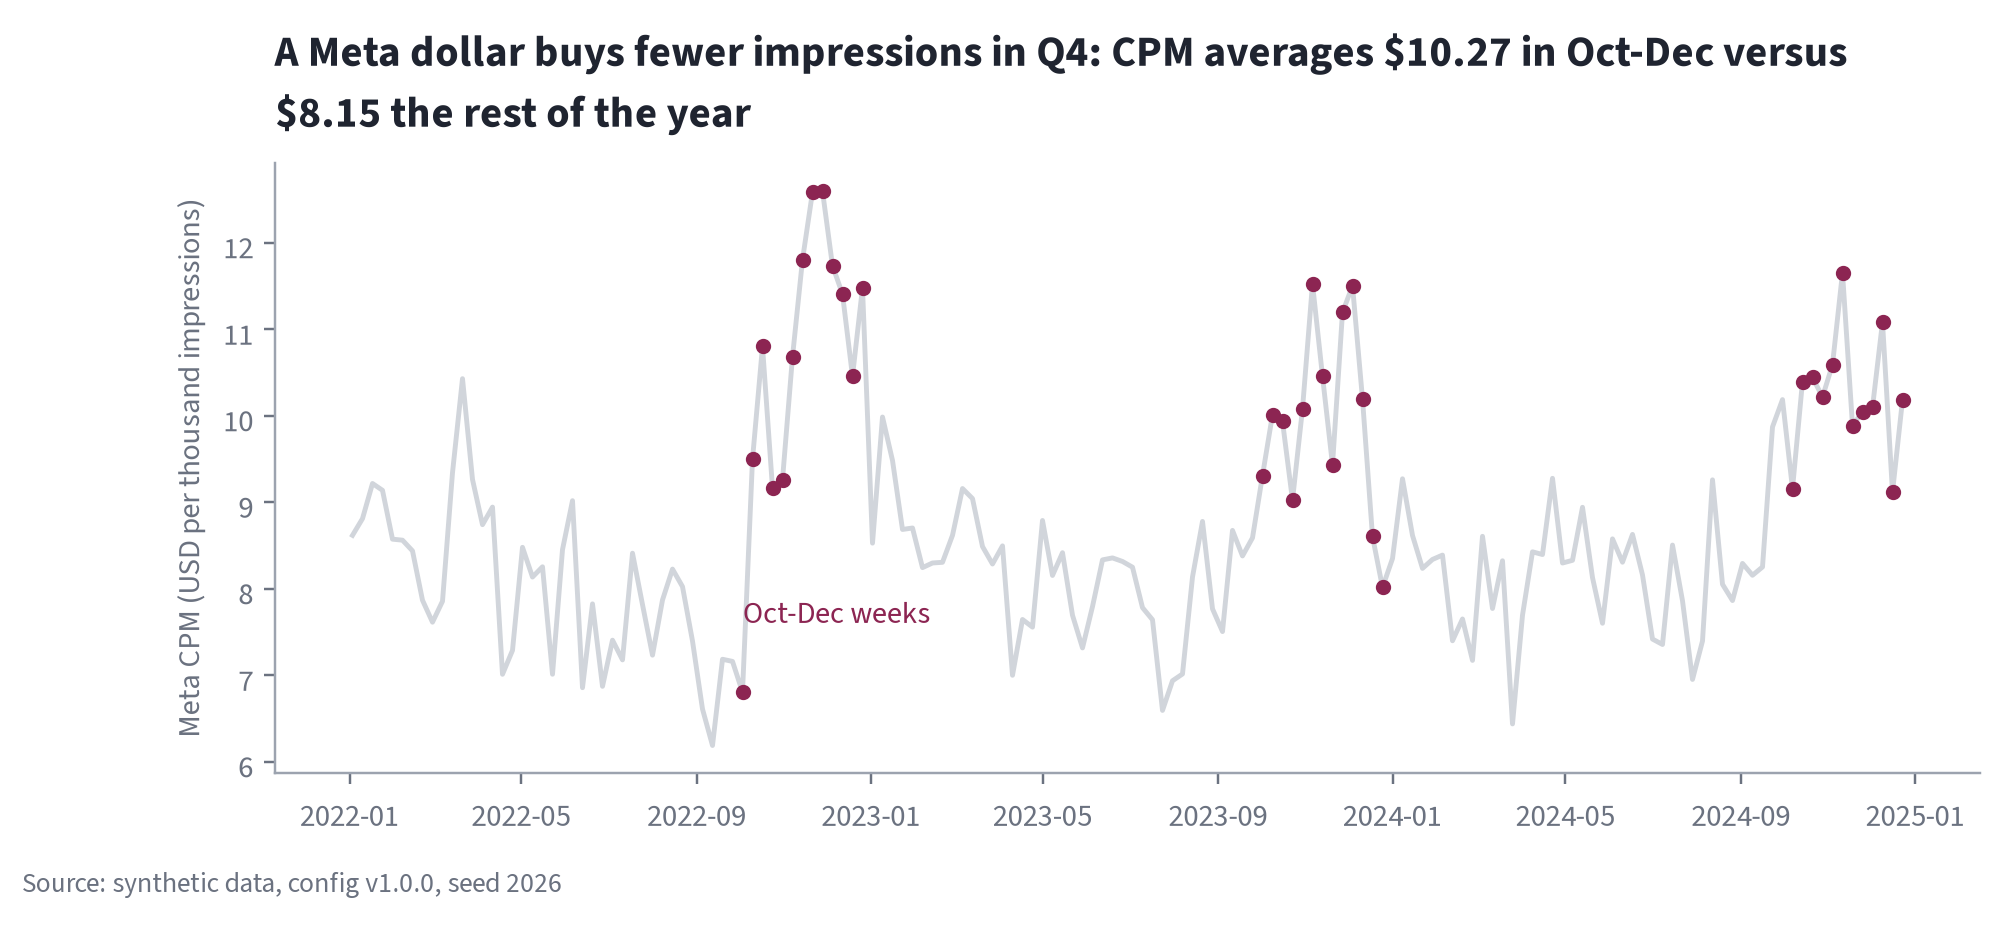

In [10]:
# 4) Meta: CPM over time (impressions = spend / CPM, and CPM rises in Q4)
if "meta_impressions" in obs.columns:
    cpm = obs["meta_spend"] / obs["meta_impressions"]  # USD per thousand impressions
    q4 = dates.dt.month >= 10
    word = "fewer" if cpm[q4].mean() > cpm[~q4].mean() else "more"
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.plot(dates, cpm, color=LIGHT, lw=1.6)
    ax.scatter(dates[q4], cpm[q4], color=MULBERRY, s=16, zorder=3)
    ax.text(dates[q4].iloc[0], cpm[q4].iloc[0] + 0.8, "Oct-Dec weeks", color=MULBERRY, fontsize=10)
    ax.set_ylabel("Meta CPM (USD per thousand impressions)")
    finish(
        ax,
        f"A Meta dollar buys {word} impressions in Q4: "
        f"CPM averages \\${cpm[q4].mean():.2f} in Oct-Dec "
        f"versus \\${cpm[~q4].mean():.2f} the rest of the year",
        SOURCE,
    )
    plt.show()

## 6. The ground truth, as numbers

**ROAS** is return on ad spend: sales contributed per unit of spend.

- *Design* values come from the config at a typical week's carryover level.
- *Realized* values are the total contribution divided by total spend over the whole period. **Score models against the realized value.** The two differ because of diminishing returns and timing.
- *Marginal* ROAS is the return on one more unit of spend at the typical week, and is always lower than the average where there is saturation.

In [11]:
design, real = truth["design_values_typical_week"], truth["realized"]
roas = pd.DataFrame(
    {
        k: {
            "mean spend (k USD/wk)": real[k]["mean_spend"],
            "design avg ROAS": design[k]["typical_week_avg_roas"],
            "realized avg ROAS": real[k]["avg_roas"],
            "design marginal ROAS": design[k]["typical_week_marginal_roas"],
            "share of sales": real[k]["share_of_sales"],
        }
        for k in cfg["channels"]
    }
).T
roas.round(2)

,mean spend (k USD/wk),design avg ROAS,realized avg ROAS,design marginal ROAS,share of sales
tv,60.36,1.83,1.81,0.92,0.08
ooh,19.83,1.77,1.77,1.20,0.02
meta,40.42,1.99,1.86,1.08,0.05
youtube_display,29.20,1.50,1.47,0.75,0.03
search,25.45,3.06,2.94,1.50,0.05


### Promotions drawn for this seed

Each event draws its own uplift (a share of that week's baseline). Both numbers are stored in the truth file.

In [12]:
pd.DataFrame(truth["promo_events"]).assign(
    weeks=lambda d: d["weeks"].apply(lambda x: ", ".join(map(str, x))),
    uplift=lambda d: d["uplift"].round(3),
)

,name,year,weeks,uplift
0,spring_sale,2022,"14, 15",0.148
1,summer_sale,2022,"27, 28",0.093
2,back_to_school,2022,33,0.115
3,black_friday,2022,46,0.137
4,spring_sale,2023,"66, 67",0.151
5,summer_sale,2023,"79, 80",0.110
6,back_to_school,2023,86,0.086
7,black_friday,2023,98,0.125
8,spring_sale,2024,"118, 119",0.117
9,summer_sale,2024,"131, 132",0.137


### How strongly spend follows things the model cannot see

Spend is not random. These correlations show how it follows the calendar (which a model can control for) and hidden demand (which it cannot). They are **diagnostics to report, not dials to tune**: if you change the config after seeing them, save it as a new config version.

In [13]:
diag = pd.DataFrame(
    {
        k: {
            "r with seasonal index": real[k]["corr_spend_vs_seasonal_index"],
            "r with promo flag": real[k]["corr_spend_vs_promo_flag"],
            "r with hidden demand shock": real[k]["corr_spend_vs_latent_shock"],
            "r with sales noise": real[k]["corr_spend_vs_sales_noise"],
        }
        for k in cfg["channels"]
    }
).T
print(
    "Search clicks that were not incremental:",
    f"{real['search_extras']['share_of_observed_clicks_not_incremental']:.1%}",
)
print(
    "Correlation of the observed search-volume proxy with true query volume:",
    f"{real['search_extras']['corr_observed_volume_vs_true_query_volume']:.2f}",
)
diag.round(2)

Search clicks that were not incremental: 39.4%
Correlation of the observed search-volume proxy with true query volume: 0.74


,r with seasonal index,r with promo flag,r with hidden demand shock,r with sales noise
tv,0.74,0.23,0.00,-0.12
ooh,0.64,0.29,-0.03,-0.18
meta,0.73,0.32,0.01,-0.11
youtube_display,0.61,0.30,0.05,-0.12
search,0.60,0.41,0.24,-0.09


### Optional: switch the hidden confounding off

The same config and seed with chasing and demand tracking set to zero. If the hidden correlation collapses, you have confirmed that the confounding in the main dataset is coming from those mechanisms. Use it as a sanity check for any model you build: with confounding off, recovery should get much easier.

In [14]:
obs_off, truth_off = simulate(cfg, seed, config_sha256=config_sha, confounding=False)
pd.DataFrame(
    {
        "r(spend, hidden demand), confounding ON": {
            k: real[k]["corr_spend_vs_latent_shock"] for k in cfg["channels"]
        },
        "r(spend, hidden demand), confounding OFF": {
            k: truth_off["realized"][k]["corr_spend_vs_latent_shock"] for k in cfg["channels"]
        },
    }
).round(2)

,"r(spend, hidden demand), confounding ON","r(spend, hidden demand), confounding OFF"
tv,0.00,0.00
ooh,-0.03,-0.03
meta,0.01,-0.03
youtube_display,0.05,0.03
search,0.24,0.05


## 7. Save the two files

Re-running with the same config and seed overwrites these files with identical bytes.

In [15]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
csv_path, json_path = OUT_DIR / "synthetic_mmm_data.csv", OUT_DIR / "ground_truth.json"
obs.to_csv(csv_path, index=False)
json_path.write_text(json.dumps(_jsonable(truth), indent=1))

check = pd.read_csv(csv_path)
assert check.shape == obs.shape and not any(c.startswith("true_") for c in check.columns)
print(
    f"Saved {csv_path.relative_to(REPO)}  ({csv_path.stat().st_size / 1024:.0f} KB, "
    f"{check.shape[0]} x {check.shape[1]})"
)
print(f"Saved {json_path.relative_to(REPO)}  ({json_path.stat().st_size / 1024:.0f} KB)")

Saved data/synthetic_mmm_data.csv  (24 KB, 156 x 18)
Saved data/ground_truth.json  (69 KB)


## 8. Using the data

1. **Model only the observed columns** in `synthetic_mmm_data.csv`. Do not open `ground_truth.json` until you have a fitted model and want to score it.
2. **Score against the realized values** in section 6, per channel: estimated contribution and ROAS against the known ones.
3. **Word results carefully.** Say a model "recovers the known effect" or gives "an estimated contribution close to the simulated one" for *this* data-generating process. Do not say the model "caused" anything, and do not claim the result holds for real accounts. One dataset is one draw: to separate bias from bad luck, repeat across many seeds.
4. **Report the limits.** The parameters are illustrative, not calibrated to any real business. See the README for the full list of simplifications.